# Questão 1 — MLP para aproximação de função e regressão

**Aprendizado Profundo (UFPB, 2026.2)**

Neste notebook resolvemos a Questão 1 da lista usando uma **Rede Perceptron de Múltiplas Camadas (MLP)** em PyTorch:

- **Parte a)** aproximar a função $f(x) = 3\sin(2x) + 2\cos(5x) + 0{,}5x^2$, com $0 \le x \le 10$.
- **Parte b)** prever a progressão do diabetes com o *Diabetes Dataset* do scikit-learn (regressão).

Em ambas as partes seguimos o mesmo roteiro: preparar os dados, definir a rede, treinar, olhar as curvas de erro e medir **MAE**, **MSE** e **RMSE**.

## 0. Preparação

Importamos as bibliotecas, fixamos as sementes aleatórias (para os resultados serem reproduzíveis por todo o grupo) e definimos duas funções auxiliares que serão usadas nas duas partes:

- `metricas`: calcula MAE, MSE e RMSE.
- `treinar`: laço de treinamento que guarda o erro de treino e o de validação a cada época.

In [1]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams["figure.dpi"] = 100


def para_tensor(a):
    return torch.tensor(a, dtype=torch.float32)


def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MAE": mean_absolute_error(y_real, y_pred), "MSE": mse, "RMSE": np.sqrt(mse)}


def treinar(modelo, X_tr, y_tr, X_val, y_val, epocas, lr, weight_decay=0.0, restaurar_melhor=False):
    """Treina com Adam e MSE (lote completo). Retorna o histórico de erros por época."""
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    perda = nn.MSELoss()
    hist = {"treino": [], "validacao": []}
    melhor_val, melhores_pesos = float("inf"), None

    for _ in range(epocas):
        modelo.train()
        otimizador.zero_grad()
        erro_tr = perda(modelo(X_tr), y_tr)
        erro_tr.backward()
        otimizador.step()

        modelo.eval()
        with torch.no_grad():
            erro_val = perda(modelo(X_val), y_val).item()
        hist["treino"].append(erro_tr.item())
        hist["validacao"].append(erro_val)

        if erro_val < melhor_val:
            melhor_val, melhores_pesos = erro_val, copy.deepcopy(modelo.state_dict())

    if restaurar_melhor:
        modelo.load_state_dict(melhores_pesos)
    return hist


def plotar_curvas(hist, titulo):
    plt.figure(figsize=(7, 4))
    plt.plot(hist["treino"], label="Treino")
    plt.plot(hist["validacao"], label="Validação")
    plt.yscale("log")
    plt.xlabel("Época")
    plt.ylabel("Erro (MSE, escala normalizada, log)")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

**O que foi feito:** o notebook está pronto para uso. Note que o treinamento usa o *lote completo* (todos os dados de treino de uma vez a cada época). Isso é simples e, com tão poucos dados, é rápido. Todas as curvas de erro usam escala logarítmica no eixo y, porque o erro cai várias ordens de grandeza.

---
# Parte a) Aproximação da função $f(x) = 3\sin(2x) + 2\cos(5x) + 0{,}5x^2$

## a.1 Geração dos dados

Definimos a função e sorteamos **1000 valores de $x$** uniformemente em $[0, 10]$. A saída desejada é $f(x)$. Depois separamos **80% para treino** e **20% para teste**: a rede só aprende com o treino, e o teste serve para acompanhar o desempenho durante o treinamento (como pede o enunciado).

Treino: 800 amostras | Teste: 200 amostras


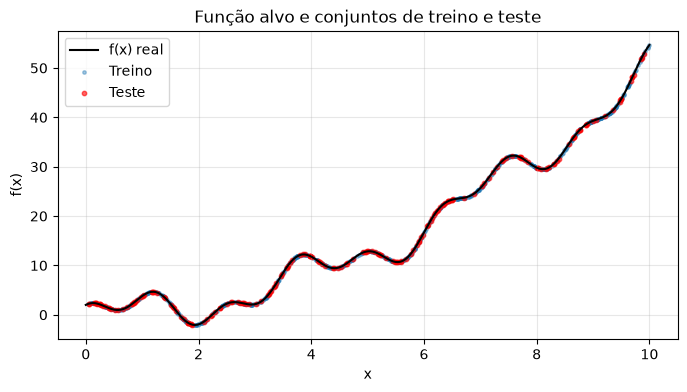

In [2]:
def f(x):
    return 3 * np.sin(2 * x) + 2 * np.cos(5 * x) + 0.5 * x**2


x = np.random.uniform(0, 10, size=(1000, 1))
y = f(x)

x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=SEED)
print(f"Treino: {len(x_tr)} amostras | Teste: {len(x_te)} amostras")

x_grade = np.linspace(0, 10, 500).reshape(-1, 1)  # grade fina, só para desenhar curvas
plt.figure(figsize=(8, 4))
plt.plot(x_grade, f(x_grade), color="black", label="f(x) real")
plt.scatter(x_tr, y_tr, s=6, alpha=0.4, label="Treino")
plt.scatter(x_te, y_te, s=10, color="red", alpha=0.6, label="Teste")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Função alvo e conjuntos de treino e teste")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Resultado:** a função tem uma tendência crescente (o termo $0{,}5x^2$) com oscilações rápidas por cima (os termos seno e cosseno). É isso que a MLP precisa capturar. Os pontos de treino e de teste cobrem todo o intervalo.

## a.2 Normalização

Redes neurais treinam melhor quando entradas e saídas têm escala parecida (média 0, desvio 1). Aplicamos `StandardScaler` em $x$ e em $f(x)$, **ajustando os scalers apenas com o treino** para não vazar informação do teste. Quando formos calcular as métricas, voltamos para a escala original.

In [3]:
sc_x = StandardScaler().fit(x_tr)
sc_y = StandardScaler().fit(y_tr)

X_tr, X_te = para_tensor(sc_x.transform(x_tr)), para_tensor(sc_x.transform(x_te))
Y_tr, Y_te = para_tensor(sc_y.transform(y_tr)), para_tensor(sc_y.transform(y_te))
print("Média e desvio de x (treino):", sc_x.mean_[0].round(2), sc_x.scale_[0].round(2))
print("Média e desvio de f(x) (treino):", sc_y.mean_[0].round(2), sc_y.scale_[0].round(2))

Média e desvio de x (treino): 4.95 2.93
Média e desvio de f(x) (treino): 16.65 14.88


**Resultado:** guardamos a média e o desvio do treino. Os tensores `X_*` e `Y_*` são os dados normalizados que a rede vai usar.

## a.3 Arquitetura da rede

Usamos uma MLP com **1 entrada ($x$), 3 camadas ocultas de 64 neurônios e 1 saída ($f(x)$)**. A ativação é a **tangente hiperbólica (Tanh)**, que é suave e funciona bem para aproximar funções contínuas e oscilantes. Na saída não há ativação (regressão).

Treinamos com o otimizador **Adam** (taxa de aprendizado 0,001) e erro quadrático médio (**MSE**) por **5000 épocas**.

In [4]:
modelo_a = nn.Sequential(
    nn.Linear(1, 64), nn.Tanh(),
    nn.Linear(64, 64), nn.Tanh(),
    nn.Linear(64, 64), nn.Tanh(),
    nn.Linear(64, 1),
)
print(modelo_a)
print("Parâmetros treináveis:", sum(p.numel() for p in modelo_a.parameters()))

Sequential(
  (0): Linear(in_features=1, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): Tanh()
  (6): Linear(in_features=64, out_features=1, bias=True)
)
Parâmetros treináveis: 8513


**Resultado:** a rede tem 8.513 parâmetros, mais do que as 800 amostras de treino. Normalmente isso seria um alerta de *overfitting*, mas aqui os dados vêm de uma função sem ruído, então não há ruído para a rede decorar. Vamos confirmar isso olhando a curva de validação.

## a.4 Treinamento

Treinamos usando **somente o conjunto de treino**. A cada época, calculamos também o erro no conjunto de teste (sem usá-lo para atualizar os pesos), para montar a curva de validação.

In [5]:
hist_a = treinar(modelo_a, X_tr, Y_tr, X_te, Y_te, epocas=5000, lr=1e-3)
print(f"Erro final (normalizado) -> treino: {hist_a['treino'][-1]:.5f} | teste: {hist_a['validacao'][-1]:.5f}")

Erro final (normalizado) -> treino: 0.00005 | teste: 0.00007


**Resultado:** o erro final é muito pequeno nos dois conjuntos. Vamos ver a evolução ao longo das épocas na próxima seção.

## a.5 Curvas de erro de treinamento e de validação

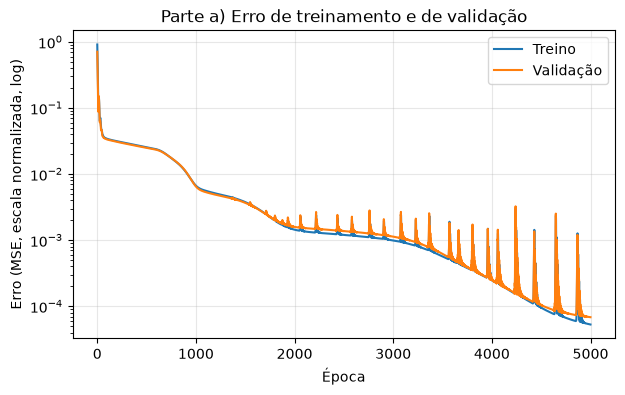

In [6]:
plotar_curvas(hist_a, "Parte a) Erro de treinamento e de validação")

**Análise:** as duas curvas descem juntas e ficam praticamente coladas, o que indica que a rede **generaliza bem** (não há *overfitting*: o erro de teste não se afasta do de treino). Há um patamar até cerca da época 600, em que a rede captura só a tendência geral (a parábola), e uma queda depois, quando ela passa a ajustar as oscilações. Os picos esporádicos são instabilidades normais do Adam com lote completo e taxa de aprendizado fixa; o erro volta a cair logo em seguida.

## a.6 Função real × função aproximada

Geramos a saída da rede numa grade fina de $x$ e comparamos com a função real.

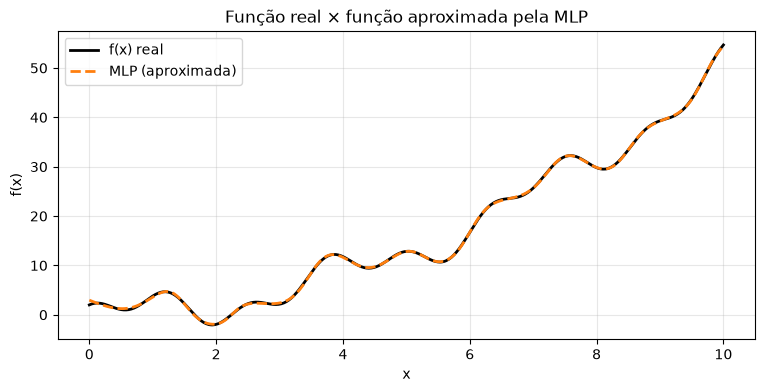

In [7]:
modelo_a.eval()
with torch.no_grad():
    y_grade_pred = sc_y.inverse_transform(modelo_a(para_tensor(sc_x.transform(x_grade))).numpy())

plt.figure(figsize=(9, 4))
plt.plot(x_grade, f(x_grade), color="black", linewidth=2, label="f(x) real")
plt.plot(x_grade, y_grade_pred, color="tab:orange", linestyle="--", linewidth=2, label="MLP (aproximada)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Função real × função aproximada pela MLP")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Análise:** as duas curvas praticamente se sobrepõem em todo o intervalo, inclusive nas oscilações rápidas. A rede aprendeu tanto a tendência quanto os detalhes da função.

## a.7 Métricas no conjunto de teste

Convertemos as previsões de volta para a escala original e calculamos **MAE** (erro médio absoluto), **MSE** (erro quadrático médio) e **RMSE** (raiz do MSE, na mesma unidade de $f(x)$). Mostramos também as métricas do treino para comparação.

In [8]:
with torch.no_grad():
    pred_tr = sc_y.inverse_transform(modelo_a(X_tr).numpy())
    pred_te = sc_y.inverse_transform(modelo_a(X_te).numpy())

tabela_a = pd.DataFrame({"Treino": metricas(y_tr, pred_tr), "Teste": metricas(y_te, pred_te)}).T
tabela_a.round(4)

,MAE,MSE,RMSE
Treino,0.0847,0.0117,0.1083
Teste,0.0964,0.0151,0.1230


**Análise:** o erro no teste é parecido com o do treino, confirmando a boa generalização. Como $f(x)$ varia de aproximadamente $-5$ a $55$, um RMSE pequeno significa que a rede erra em média muito pouco em relação à amplitude da função.

## a.8 Curva real × curva predita (conjunto de teste)

Ordenamos os pontos de teste por $x$ para desenhar as curvas. À direita, um gráfico de dispersão do valor real contra o predito: pontos sobre a diagonal significam previsões perfeitas.

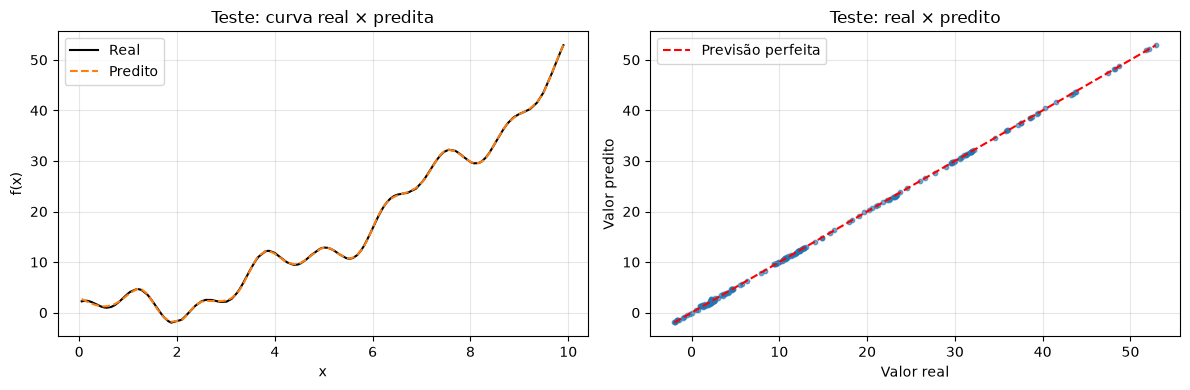

In [9]:
ordem = np.argsort(x_te[:, 0])
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].plot(x_te[ordem], y_te[ordem], color="black", label="Real")
eixos[0].plot(x_te[ordem], pred_te[ordem], color="tab:orange", linestyle="--", label="Predito")
eixos[0].set_xlabel("x")
eixos[0].set_ylabel("f(x)")
eixos[0].set_title("Teste: curva real × predita")
eixos[0].legend()
eixos[0].grid(alpha=0.3)

eixos[1].scatter(y_te, pred_te, s=10, alpha=0.6)
lim = [y_te.min(), y_te.max()]
eixos[1].plot(lim, lim, color="red", linestyle="--", label="Previsão perfeita")
eixos[1].set_xlabel("Valor real")
eixos[1].set_ylabel("Valor predito")
eixos[1].set_title("Teste: real × predito")
eixos[1].legend()
eixos[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Análise:** a curva predita acompanha a real em todos os pontos de teste, e a dispersão fica colada na diagonal. Isso conclui a parte a): a MLP aproxima bem a função.

---
# Parte b) Regressão com o Diabetes Dataset

O dataset tem **442 pacientes**, **10 atributos** (idade, sexo, IMC, pressão arterial e seis medidas de sangue, `s1` a `s6`) e um **alvo quantitativo**: a progressão da doença um ano após a medição inicial. Queremos prever esse alvo a partir dos atributos.

## b.1 Carregamento e análise exploratória

Carregamos com `scaled=False` para ver os atributos nas unidades originais (por padrão o scikit-learn já os entrega centralizados e escalados, o que atrapalharia a exploração). Em seguida olhamos as primeiras linhas, estatísticas descritivas e se há valores ausentes.

In [10]:
dados = load_diabetes(as_frame=True, scaled=False)
df = dados.frame
print("Formato:", df.shape)
print("Valores ausentes por coluna:", int(df.isna().sum().sum()), "no total")
df.head()

Formato: (442, 11)
Valores ausentes por coluna: 0 no total


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [11]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00


**Resultado:** são 442 linhas e 11 colunas, **sem valores ausentes**, então não precisamos de imputação. Os atributos têm escalas bem diferentes (por exemplo, `age` vai até 79 e `s4` fica em torno de 4), o que justifica a normalização que faremos adiante. A coluna `sex` é binária (1 e 2).

### Distribuições

Histogramas do alvo e de cada atributo, para ver formato e possíveis assimetrias.

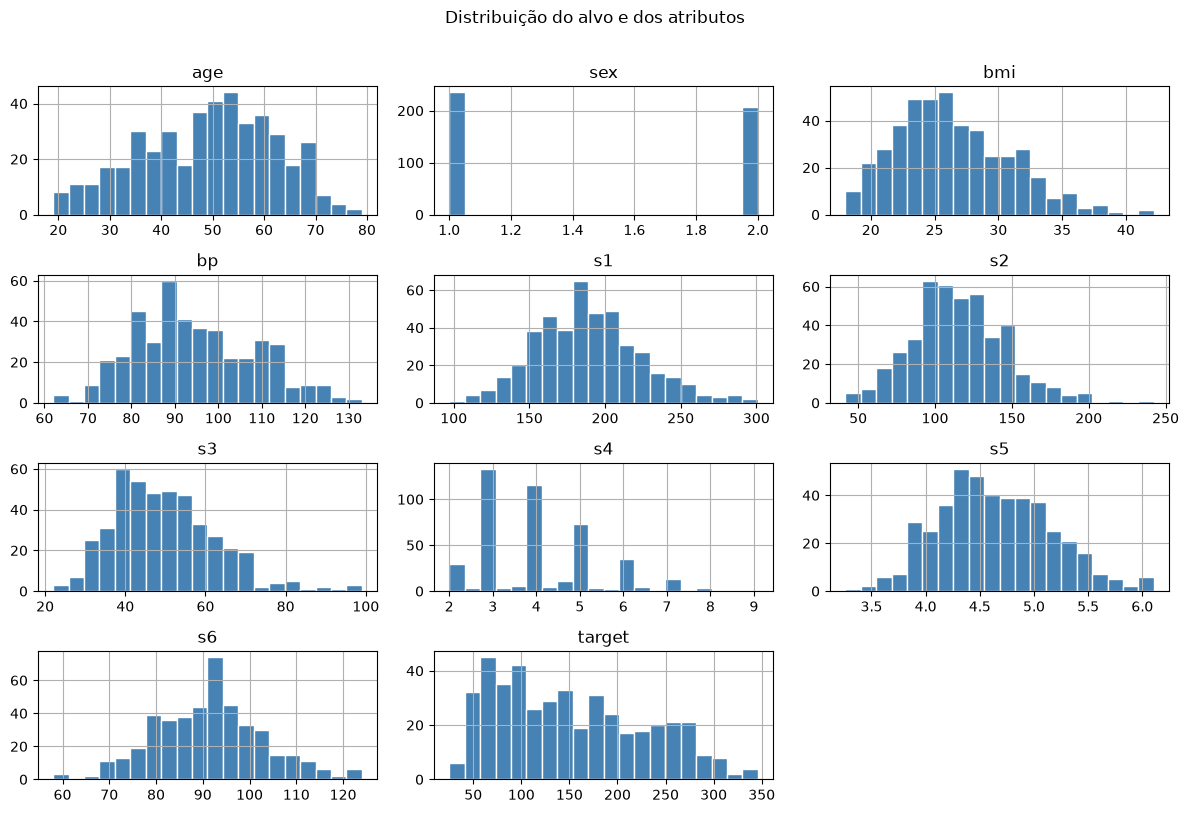

In [12]:
df.hist(bins=20, figsize=(12, 8), color="steelblue", edgecolor="white")
plt.suptitle("Distribuição do alvo e dos atributos", y=1.01)
plt.tight_layout()
plt.show()

**Análise:** o alvo (`target`) tem distribuição um pouco assimétrica à direita: a maioria dos pacientes tem progressão baixa ou moderada e poucos têm valores altos. Os atributos têm formatos variados, e `sex` aparece como duas barras (variável binária). Não há valores absurdos que exijam remoção de *outliers*.

### Correlações

A matriz de correlação mostra quais atributos se relacionam com o alvo e quais se relacionam entre si (atributos muito correlacionados são redundantes).

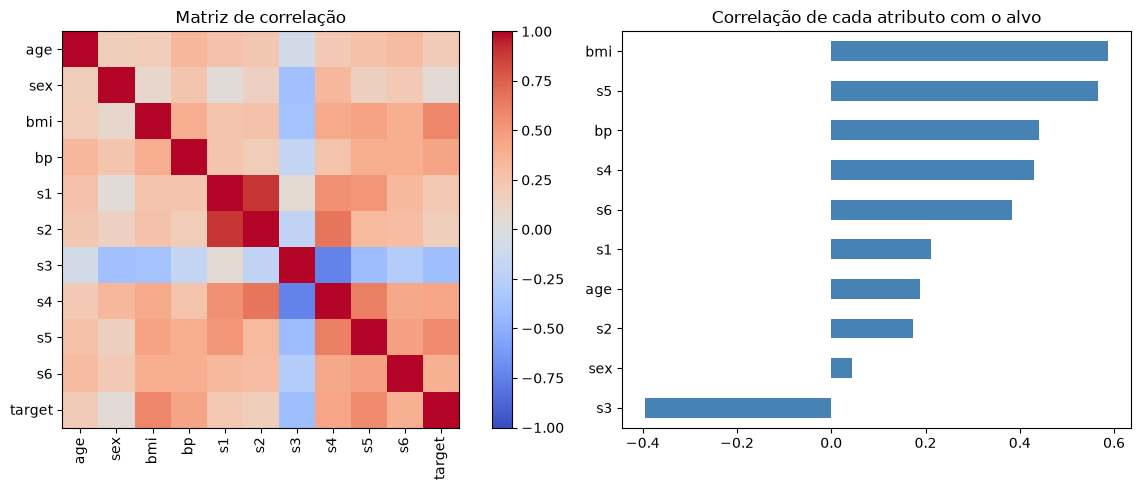

In [13]:
corr = df.corr()
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})

im = eixos[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
eixos[0].set_xticks(range(len(corr)), corr.columns, rotation=90)
eixos[0].set_yticks(range(len(corr)), corr.columns)
eixos[0].set_title("Matriz de correlação")
fig.colorbar(im, ax=eixos[0], fraction=0.046)

corr["target"].drop("target").sort_values().plot.barh(ax=eixos[1], color="steelblue")
eixos[1].set_title("Correlação de cada atributo com o alvo")
plt.tight_layout()
plt.show()

**Análise:** os atributos mais correlacionados com a progressão da doença são `bmi` (IMC), `s5` e `bp` (pressão arterial), todos positivos. Há também forte correlação entre alguns atributos de sangue, como `s1` e `s2`, o que indica certa redundância entre eles; `s3` é o único com correlação negativa relevante com o alvo. Como a MLP aprende combinações dos atributos, mantemos todos.

## b.2 Divisão dos dados e normalização

Como o dataset é pequeno, dividimos em **70% treino, 15% validação e 15% teste**:

- **treino**: ajusta os pesos;
- **validação**: acompanha o treinamento e escolhe a melhor época;
- **teste**: usado só no final, para medir o desempenho real.

Os atributos e o alvo são normalizados com `StandardScaler`, ajustado **somente no treino**. As métricas serão calculadas na escala original do alvo.

In [14]:
X = df.drop(columns="target").values
y = df[["target"]].values

X_tr0, X_tmp, y_tr0, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_va0, X_te0, y_va0, y_te0 = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED)
print(f"Treino: {len(X_tr0)} | Validação: {len(X_va0)} | Teste: {len(X_te0)}")

sc_X_b = StandardScaler().fit(X_tr0)
sc_y_b = StandardScaler().fit(y_tr0)

XB_tr, XB_va, XB_te = (para_tensor(sc_X_b.transform(a)) for a in (X_tr0, X_va0, X_te0))
YB_tr, YB_va, YB_te = (para_tensor(sc_y_b.transform(a)) for a in (y_tr0, y_va0, y_te0))

Treino: 309 | Validação: 66 | Teste: 67


**Resultado:** os três conjuntos estão prontos e normalizados. Os dados de validação e teste foram transformados com a média e o desvio calculados no treino.

## b.3 Arquitetura da rede

Como há poucos dados, usamos uma rede pequena para reduzir o risco de *overfitting*: **10 entradas, duas camadas ocultas (32 e 16 neurônios) com ativação ReLU, e 1 saída**. Adicionamos também **regularização L2** (`weight_decay`) e **restauramos os pesos da melhor época de validação**, o que funciona como parada antecipada (*early stopping*).

In [15]:
modelo_b = nn.Sequential(
    nn.Linear(10, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1),
)
print(modelo_b)
print("Parâmetros treináveis:", sum(p.numel() for p in modelo_b.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)
Parâmetros treináveis: 897


**Resultado:** cerca de 900 parâmetros para ~300 amostras de treino. Ainda é um pouco, por isso a regularização é importante.

## b.4 Treinamento e curvas de erro

Treinamos por 500 épocas com Adam (taxa 0,001) e MSE, e plotamos as curvas de treino e validação.

Melhor época (menor erro de validação): 120


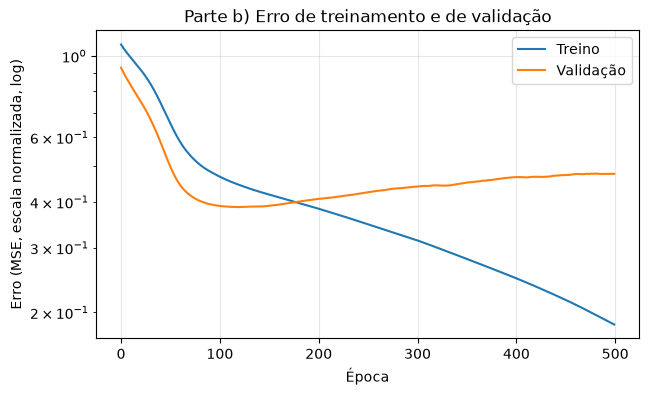

In [16]:
hist_b = treinar(modelo_b, XB_tr, YB_tr, XB_va, YB_va, epocas=500, lr=1e-3, weight_decay=1e-3, restaurar_melhor=True)
melhor_epoca = int(np.argmin(hist_b["validacao"])) + 1
print(f"Melhor época (menor erro de validação): {melhor_epoca}")
plotar_curvas(hist_b, "Parte b) Erro de treinamento e de validação")

**Análise:** o erro de treino cai continuamente, enquanto o de validação atinge o mínimo por volta da época 120 e depois volta a subir. Esse afastamento é *overfitting*: a rede passa a decorar o treino. Por isso os pesos usados daqui em diante são os da melhor época de validação, e não os da última.

## b.5 Métricas e comparação com referências

Calculamos MAE, MSE e RMSE na escala original do alvo para treino, validação e teste. Para dar contexto, comparamos com duas referências simples: **prever sempre a média do treino** (o pior razoável) e uma **regressão linear** (um modelo bem mais simples que a MLP).

In [17]:
modelo_b.eval()
with torch.no_grad():
    previsoes = {nome: sc_y_b.inverse_transform(modelo_b(X_).numpy())
                 for nome, X_ in {"Treino": XB_tr, "Validação": XB_va, "Teste": XB_te}.items()}
reais = {"Treino": y_tr0, "Validação": y_va0, "Teste": y_te0}

tabela_b = pd.DataFrame({n: metricas(reais[n], previsoes[n]) for n in reais}).T

# Referências, avaliadas no teste
media = np.full_like(y_te0, y_tr0.mean())
linear = LinearRegression().fit(sc_X_b.transform(X_tr0), y_tr0).predict(sc_X_b.transform(X_te0))
referencias = pd.DataFrame({"Média do treino (teste)": metricas(y_te0, media),
                            "Regressão linear (teste)": metricas(y_te0, linear)}).T

display(tabela_b.round(2))
display(referencias.round(2))

,MAE,MSE,RMSE
Treino,42.92,2734.18,52.29
Validação,37.92,2382.02,48.81
Teste,48.20,3289.07,57.35


,MAE,MSE,RMSE
Média do treino (teste),66.45,5706.61,75.54
Regressão linear (teste),45.57,3139.37,56.03


**Análise:** o RMSE da MLP no teste (≈ 57) fica bem abaixo do de "prever a média" (≈ 76), então a rede de fato aprendeu algo útil. Mas ele é praticamente igual ao da regressão linear (≈ 56), que até é um pouco melhor. Isso é esperado: neste dataset a relação entre os atributos e o alvo é em grande parte linear e há poucos dados, então a não linearidade da MLP não traz ganho. Com 442 amostras, o conjunto de teste tem só ~67 pacientes, então as métricas variam um pouco conforme a divisão escolhida.

## b.6 Valores reais × valores preditos

No gráfico de dispersão, cada ponto é um paciente do conjunto de teste. Quanto mais perto da diagonal, melhor a previsão. À direita, os dados ordenados pelo valor real, para comparar as curvas.

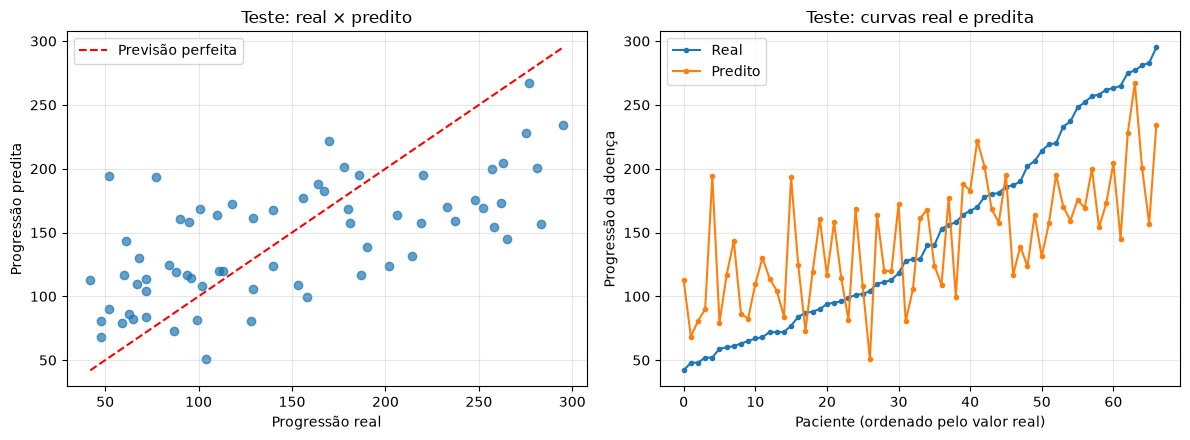

In [18]:
real, pred = y_te0[:, 0], previsoes["Teste"][:, 0]
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

eixos[0].scatter(real, pred, alpha=0.7)
lim = [real.min(), real.max()]
eixos[0].plot(lim, lim, color="red", linestyle="--", label="Previsão perfeita")
eixos[0].set_xlabel("Progressão real")
eixos[0].set_ylabel("Progressão predita")
eixos[0].set_title("Teste: real × predito")
eixos[0].legend()
eixos[0].grid(alpha=0.3)

ordem = np.argsort(real)
eixos[1].plot(real[ordem], label="Real", marker="o", markersize=3)
eixos[1].plot(pred[ordem], label="Predito", marker="o", markersize=3)
eixos[1].set_xlabel("Paciente (ordenado pelo valor real)")
eixos[1].set_ylabel("Progressão da doença")
eixos[1].set_title("Teste: curvas real e predita")
eixos[1].legend()
eixos[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Análise:** os pontos seguem a tendência da diagonal, mas com bastante dispersão: a rede acerta a direção (pacientes com progressão alta recebem previsões altas), porém erra por dezenas de unidades em vários casos. A rede também tende a "puxar para o meio", subestimando os valores mais altos e superestimando os mais baixos, comportamento comum quando há ruído nos dados e poucas amostras.

---
# Conclusões

- **Parte a):** a MLP (3 camadas ocultas, Tanh) aproximou a função com erro muito baixo e sem *overfitting*, capturando a tendência quadrática e as oscilações.
- **Parte b):** a MLP aprendeu a prever a progressão do diabetes bem melhor que um baseline de média, com desempenho equivalente ao da regressão linear (RMSE ≈ 57 contra ≈ 56 no teste). O dataset é pequeno e ruidoso, então o limite de qualidade é dado mais pelos dados do que pela arquitetura.
- A diferença entre as duas partes mostra que o resultado depende muito da natureza do problema: uma função determinística e sem ruído pode ser aproximada com precisão altíssima, enquanto dados reais têm erro irredutível.